✅ Loaded existing store with 13 embeddings.
✅ Setup complete: directories created, LangChain LLM initialized.
🧠 Sample Query Test (LangChain-based):
✅ test_query completed in 4.239s
Answer: GDPR states that retention schedules must reflect purpose limitation and storage minimization, ensuring that expired records are deleted or anonymized in a verifiable manner.  
Citation: "10. Retention and Deletion 10.1 Retention schedules reflect purpose limitation and storage minimization. 10.2 Expired records are deleted or anonymized in a verifiable manner."  
Confidence: High
🧩 Processing GDPR_Sample_Compliance.pdf
🧩 Processing FCC_Telecom_Regulations.pdf
🧩 Processing HIPAA_Sample_Compliance.pdf
🧩 Processing Company_DataPolicy_Simulated.pdf
🧩 Processing AI_Ethical_Use_Guidelines.pdf
✅ Data preparation complete (16 chunks).
✅ Generated 15 fine-tuning examples at data/finetuning/finetune_data.jsonl


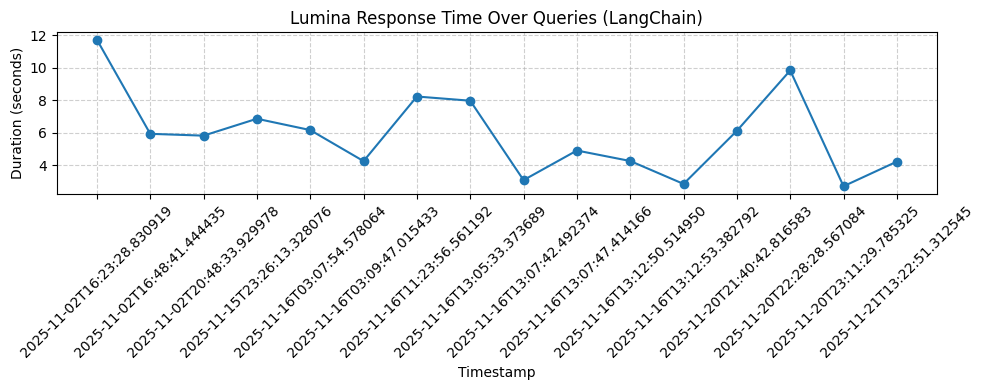

In [1]:
# %% [markdown]
# # Lumina AI — Assessment & Fine-Tuning Pipeline (LangChain-integrated)
#
# This notebook runs the end-to-end data and performance evaluation process for Lumina.
# - Refine the generative AI model and improve the efficiency of the fine-tuning process **using LangChain**.
#
# **Steps:**
# 1️⃣ Measure performance of query responses (via a LangChain chain)  
# 2️⃣ Clean and preprocess PDF data  
# 3️⃣ Generate fine-tuning samples (Q&A) using LangChain  
# 4️⃣ Visualize latency results  
#

# %%
import os
import json
import time
import re
import random
import matplotlib.pyplot as plt
from datetime import datetime

from utils.pdf_parser import extract_text_from_pdf
from utils.embed_store import PersistentEmbedStore as EmbedStore

# LangChain imports
from langchain_openai import ChatOpenAI
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser


os.environ["LANGCHAIN_TRACING_V2"] = "true"
os.environ["LANGCHAIN_ENDPOINT"] = "https://api.smith.langchain.com"
os.environ["LANGCHAIN_API_KEY"] = "<your-langsmith-key>"
os.environ["LANGCHAIN_PROJECT"] = "lumina-pipeline"



# Create directories
os.makedirs("data/logs", exist_ok=True)
os.makedirs("data/cleaned_texts", exist_ok=True)
os.makedirs("data/finetuning", exist_ok=True)
os.makedirs("data/testing_pdfs", exist_ok=True)

embed_store = EmbedStore()

# Initialize LLM via LangChain
llm = ChatOpenAI(model="gpt-4o-mini", temperature=0.3)

print("✅ Setup complete: directories created, LangChain LLM initialized.")
# %% [markdown]
## Environment & Dependencies for LangChain Integration

# This notebook is the dedicated **LangChain integration section** for the Lumina project.

# The following libraries are installed: 

# - `langchain` and `langchain-openai` for building chains around OpenAI models  
# - `langgraph` for defining workflow graphs with nodes and edges  
# - `langsmith` for optional tracing and observability of LangChain runs  
# - `langflow` (installed separately) for low-code, visual experimentation with LangChain flows  

#These are installed or updated with:


# pip install --upgrade langchain langchain-openai langgraph langsmith langflow

# %%
# %% [markdown]

## Overall LangChain Workflow (User Input → Retrieval → LLM → Output)

#This notebook defines a **LangChain-based workflow** that shows how data flows through Lumina from user input to final answer.

#The main steps are:

#1. **User input**  
#  A user asks a compliance question, for example by calling:  
#  `test_query("What does GDPR say about data retention?")`.

#2. **Context retrieval from FAISS (PersistentEmbedStore)**  
#   Inside `test_query`, the question is passed to `embed_store.query(question)`.  
#   This retrieves the most relevant chunks from the indexed policy PDFs (GDPR, HIPAA, FCC regulations, company data policy, AI ethics guidelines, etc.).

#3. **Prompt construction with LangChain**  
#  The retrieved `context` and original `question` are fed into a LangChain pipeline:  
#  `query_prompt → ChatOpenAI (gpt-4o-mini) → StrOutputParser`.  
# The prompt forces the answer to follow a structure: **Summary**, **Details**, and **Actionable Next Steps**, and tells the model to use **only** the provided context.

#4. **Model generation and timing**  
#  `query_chain.invoke({"question": question, "context": context})` calls the model and returns the formatted answer string.  
#  The `@log_response_time` decorator wraps `test_query`, so each run logs its latency into `data/logs/performance_log.jsonl`.

#5. **Downstream usage in the pipeline**  
# The same LangChain LLM (`llm`) is reused later to:
# - Generate fine-tuning Q&A pairs from document chunks (`qa_chain`)
# - Power the LangGraph workflow (retrieve → generate → evaluate with a feedback loop).
# %%

# %% [markdown]
# ## Step 1: Performance Assessment with LangChain
#
# Here we:
# - Build a **LangChain** pipeline (`query_chain`) for Lumina queries:
#   - `ChatPromptTemplate` → `ChatOpenAI` → `StrOutputParser`
# - Wrap it in `@log_response_time` to measure latency
# - Use your FAISS-based `EmbedStore` for context retrieval
#
# This step directly shows "refining the generative AI model" using LangChain.

# %%
# LangChain prompt for live queries (inference)
query_prompt = ChatPromptTemplate.from_messages([
   (
        "system",
        "You are Lumina, an AI compliance assistant.\n\n"
        "Rules:\n"
        "- Use ONLY the document context provided below.\n"
        "- If the answer is not in the context, reply exactly with: 'Not found in document.'\n"
        "- Do NOT hallucinate regulations, article numbers, or sections that are not visible in the context.\n"
        "- Your response MUST follow this exact format:\n"
        "  Answer: <clear, concise answer in plain English>\n"
        "  Citation: <policy/regulation name and section or a short quoted snippet from the context>\n"
        "  Confidence: <High | Medium | Low>\n"
        "- If you cannot see any explicit section/article names in the context, still answer but set\n"
        "  Citation: 'Based on provided context (no explicit section visible).'\n"
        "- Keep the answer short (3–6 sentences max) and focused on compliance, privacy, security, risk, or policy.\n"
    ),
    (
        "human",
        "Context:\n{context}\n\nQuestion:\n{question}"
    ),
])

query_chain = query_prompt | llm | StrOutputParser()

def log_response_time(func):
    """Decorator to measure and log function duration in a JSONL file."""
    def wrapper(*args, **kwargs):
        start = time.time()
        result = func(*args, **kwargs)
        end = time.time()
        duration = round(end - start, 3)
        log_entry = {
            "function": func.__name__,
            "timestamp": datetime.now().isoformat(),
            "duration_s": duration
        }
        with open("data/logs/performance_log.jsonl", "a") as f:
            f.write(json.dumps(log_entry) + "\n")
        print(f"✅ {func.__name__} completed in {duration}s")
        return result
    return wrapper

@log_response_time
def test_query(question: str) -> str:
    """
    Runs a Lumina query through the LangChain query_chain, using the FAISS embed store
    for retrieval and logging response time for performance analysis.
    """
    context = embed_store.query(question)
    return query_chain.invoke({"question": question, "context": context})

# Example test run
try:
    print("🧠 Sample Query Test (LangChain-based):")
    print(test_query("What does GDPR say about data retention?"))
except Exception as e:
    print("⚠️ Skipped live test (likely no embeddings yet):", e)

# %% [markdown]
# ## 🧹 Step 2: Data Preparation 
#
# - Read PDFs from `data/testing_pdfs/`
# - Extract raw text using `extract_text_from_pdf`
# - Clean the text (remove extra whitespace, page markers, etc.)
# - Chunk text into manageable pieces
# - Save:
#   - Cleaned `.txt` per PDF
#   - A combined `dataset.json` with `{doc, chunk}` entries

# %%
RAW_DIR = "data/testing_pdfs"
CLEAN_DIR = "data/cleaned_texts"

def clean_text(text: str) -> str:
    text = re.sub(r'\s+', ' ', text)
    text = re.sub(r'Page \d+', '', text)
    text = re.sub(r'\n{2,}', '\n', text)
    return text.strip()

def chunk_text(text: str, chunk_size=1000):
    return [text[i:i+chunk_size] for i in range(0, len(text), chunk_size)]

def prepare_data():
    dataset = []
    for file in os.listdir(RAW_DIR):
        if not file.endswith(".pdf"):
            continue
        path = os.path.join(RAW_DIR, file)
        print(f"🧩 Processing {file}")
        with open(path, "rb") as f:
            raw_bytes = f.read()
        raw_text = extract_text_from_pdf(raw_bytes)
        cleaned = clean_text(raw_text)
        chunks = chunk_text(cleaned)
        for chunk in chunks:
            dataset.append({"doc": file, "chunk": chunk})
        with open(os.path.join(CLEAN_DIR, file.replace(".pdf", ".txt")), "w") as f:
            f.write(cleaned)

    with open("data/cleaned_texts/dataset.json", "w") as f:
        json.dump(dataset, f, indent=2)
    print(f"✅ Data preparation complete ({len(dataset)} chunks).")

prepare_data()

# %% [markdown]
# ## 🧬 Step 3: Fine-Tuning Dataset Generation (with LangChain)
#
# This is where we **explicitly use LangChain to refine the fine-tuning process**:
#
# - Use a LangChain chain (`qa_chain`) to turn each chunk into a realistic:
#   - `Question: ...`
#   - `Answer: ...`
# - Parse that into JSONL `messages` format for fine-tuning.
#
# This is the core of **"improve the efficiency of your fine-tuning process using LangChain"**.

# %%
INPUT = "data/cleaned_texts/dataset.json"
OUTPUT = "data/finetuning/finetune_data.jsonl"
SYSTEM_PROMPT = "You are Lumina, a compliance expert."

# LangChain prompt to generate Q&A from a chunk
qa_prompt = ChatPromptTemplate.from_messages([
    (
        "system",
        "You are preparing high-quality training data for a compliance Q&A assistant. "
        "Given the document chunk, generate ONE realistic user question and a concise, "
        "accurate answer based ONLY on the chunk. "
        "Format the output exactly as:\n\n"
        "Question: <question text>\nAnswer: <answer text>"
    ),
    (
        "human",
        "Chunk:\n{chunk}"
    ),
])

qa_chain = qa_prompt | llm | StrOutputParser()

def parse_qa(text: str):
    """Parse 'Question: ...\\nAnswer: ...' into (q, a)."""
    match = re.search(r"Question:(.*)\nAnswer:(.*)", text, re.DOTALL | re.IGNORECASE)
    if not match:
        return None, None
    q = match.group(1).strip()
    a = match.group(2).strip()
    return q, a

def generate_finetune_dataset():
    with open(INPUT) as f:
        data = json.load(f)

    # Group chunks by document
    docs = {}
    for d in data:
        docs.setdefault(d["doc"], []).append(d["chunk"])

    examples = []
    for doc, chunks in docs.items():
        # sample up to 3 chunks per document so we don't explode API usage
        sampled_chunks = random.sample(chunks, min(3, len(chunks)))
        for chunk in sampled_chunks:
            try:
                qa_text = qa_chain.invoke({"chunk": chunk})
                q, a = parse_qa(qa_text)
                if not q or not a:
                    continue
                examples.append({
                    "messages": [
                        {"role": "system", "content": SYSTEM_PROMPT},
                        {"role": "user", "content": q},
                        {"role": "assistant", "content": a}
                    ]
                })
            except Exception as e:
                print(f"⚠️ Skipping chunk due to error: {e}")
                continue

    with open(OUTPUT, "w") as f:
        for ex in examples:
            f.write(json.dumps(ex) + "\n")

    print(f"✅ Generated {len(examples)} fine-tuning examples at {OUTPUT}")

generate_finetune_dataset()

# %% [markdown]
# ## 📊 Step 4: Performance Visualization
#
# This reuses the latency logs written in Step 1 and plots:
# - X-axis: timestamp
# - Y-axis: response duration (seconds)


# %%
def plot_performance_log():
    try:
        logs = [json.loads(line) for line in open("data/logs/performance_log.jsonl")]
    except FileNotFoundError:
        print("⚠️ No performance log found yet.")
        return

    durations = [log["duration_s"] for log in logs]
    timestamps = [log["timestamp"] for log in logs]

    if not durations:
        print("⚠️ Log file exists but has no entries yet.")
        return

    plt.figure(figsize=(10, 4))
    plt.plot(timestamps, durations, marker="o", linestyle="-")
    plt.title("Lumina Response Time Over Queries (LangChain)")
    plt.xlabel("Timestamp")
    plt.ylabel("Duration (seconds)")
    plt.xticks(rotation=45)
    plt.grid(True, linestyle="--", alpha=0.6)
    plt.tight_layout()
    plt.show()

plot_performance_log()

# %% [markdown]
# ## ✅ Pipeline Summary (LangChain-integrated)
#
# | Step                    | Tooling / Output                                                                 |
# |-------------------------|-----------------------------------------------------------------------------------|
# | Live Query Evaluation   | **LangChain** `query_chain` + FAISS + `@log_response_time` → `performance_log.jsonl` |
# | Data Preparation        | Cleaned text + chunks → `data/cleaned_texts/dataset.json`                        |
# | Fine-Tuning Dataset     | **LangChain** `qa_chain` → `data/finetuning/finetune_data.jsonl`                |
# | Performance Visualization | Matplotlib chart of response times                                             |
#
# You can now fine-tune using:
#
# ```bash
# openai api fine_tunes.create -t data/finetuning/finetune_data.jsonl -m gpt-3.5-turbo-1106
# ```
#
# In this version:
# - **LangChain is part of both the query workflow AND the fine-tuning data generation.**
# - This directly supports the assignment objective:
#   > "Refine your generative AI model and improve the efficiency of your fine-tuning process using LangChain."


In [2]:
import sys
import platform
import langchain
import langgraph
import openai
import pkg_resources

print("Python:", sys.version)
print("Platform:", platform.platform())

print("LangChain:", langchain.__version__)
print("LangChain-OpenAI:", pkg_resources.get_distribution("langchain-openai").version)
print("LangGraph:", langgraph.__version__)
print("OpenAI SDK:", openai.__version__)


Python: 3.12.8 (v3.12.8:2dc476bcb91, Dec  3 2024, 14:43:19) [Clang 13.0.0 (clang-1300.0.29.30)]
Platform: macOS-15.6.1-arm64-arm-64bit
LangChain: 1.0.5
LangChain-OpenAI: 1.0.2


/var/folders/tf/x2nxxbc975x4qlqrp2b6gjdc0000gn/T/ipykernel_89813/3619935949.py:6: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


AttributeError: module 'langgraph' has no attribute '__version__'

In [3]:
# %% 
# 🧠 LangGraph Workflow: Retrieve → Generate → Evaluate with Feedback Loop
import time
import pprint
import json
from datetime import datetime
from typing import TypedDict, Literal
from langgraph.graph import StateGraph, END
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser

class AppState(TypedDict):
    question: str
    context: str
    answer: str
    quality: Literal["unknown", "good", "bad"]
    attempts: int  # how many times we've generated an answer

# 1) Node: retrieve context from FAISS store
def lg_retrieve_node(state: AppState) -> AppState:
    ctx = embed_store.query(state["question"])
    return {**state, "context": ctx}

# 2) Node: generate answer using a LangChain chain with context
lg_prompt_with_context = ChatPromptTemplate.from_messages([
    ("system",
     "You are Lumina, an AI compliance assistant.\n\n"
     "Rules:\n"
     "- Use ONLY the document context provided below.\n"
     "- If the answer is not in the context, reply exactly with: 'Not found in document.'\n"
     "- Do NOT hallucinate.\n"
     "- Your response MUST follow this exact format:\n"
     "  Answer: <clear, concise answer in plain English>\n"
     "  Citation: <policy/regulation name and section or a short quoted snippet from the context>\n"
     "  Confidence: <High | Medium | Low>\n"
     ),
    (
        "human",
        "Context:\n{context}\n\nQuestion:\n{question}"
    ),
])
lg_chain_with_context = lg_prompt_with_context | llm | StrOutputParser()

def lg_generate_node(state: AppState) -> AppState:
    answer = lg_chain_with_context.invoke(
        {"question": state["question"], "context": state["context"]}
    )
    attempts = state.get("attempts", 0) + 1
    return {**state, "answer": answer, "quality": "unknown", "attempts": attempts}

# 3) Node: evaluate answer quality
lg_eval_prompt = ChatPromptTemplate.from_messages([
    ("system", "You are a strict evaluator. Reply ONLY with 'good' or 'bad'."),
    ("human",
     "Question: {question}\n"
     "Context: {context}\n"
     "Answer: {answer}\n\n"
     "Is this answer good or bad?")
])
lg_eval_chain = lg_eval_prompt | llm | StrOutputParser()

def lg_evaluate_node(state: AppState) -> AppState:
    quality_raw = lg_eval_chain.invoke(state)
    quality = "good" if "good" in quality_raw.lower() else "bad"
    return {**state, "quality": quality}

# Routing: decide whether to retry or end
def lg_route_after_eval(state: AppState) -> str:
    # Retry only if it's bad AND we haven't retried too many times
    if state["quality"] == "bad" and state.get("attempts", 0) < 2:
        return "retry"
    return "end"

# Build the graph
builder = StateGraph(AppState)
builder.add_node("retrieve", lg_retrieve_node)
builder.add_node("generate", lg_generate_node)
builder.add_node("evaluate", lg_evaluate_node)

builder.set_entry_point("retrieve")
builder.add_edge("retrieve", "generate")
builder.add_edge("generate", "evaluate")

builder.add_conditional_edges(
    "evaluate",
    lg_route_after_eval,
    {
        "retry": "generate",  # 🔁 feedback loop / cycle
        "end": END,
    },
)

langgraph_app = builder.compile()
print("✅ LangGraph compiled with bounded retries.")

LANGGRAPH_LOG_PATH = "data/logs/langgraph_log.jsonl"

def run_langgraph(question: str) -> AppState:
    """
    Runs the LangGraph for a given question, measures total latency,
    prints a summary, and logs it to data/logs/langgraph_log.jsonl.
    """
    initial_state: AppState = {
        "question": question,
        "context": "",
        "answer": "",
        "quality": "unknown",
        "attempts": 0,
    }

    start = time.time()
    final_state: AppState = langgraph_app.invoke(initial_state)
    latency = round(time.time() - start, 3)

    print("\n🧠 LangGraph run complete")
    print(f"Question   : {final_state['question']}")
    print(f"Quality    : {final_state['quality']}")
    print(f"Attempts   : {final_state['attempts']}")
    print(f"Latency (s): {latency}")
    print("\nAnswer preview:\n", final_state["answer"][:500])

    # Log to JSONL (optional but nice for analysis)
    log_entry = {
        "timestamp": datetime.now().isoformat(),
        "question": final_state["question"],
        "quality": final_state["quality"],
        "attempts": final_state["attempts"],
        "duration_s": latency,
    }
    os.makedirs(os.path.dirname(LANGGRAPH_LOG_PATH), exist_ok=True)
    with open(LANGGRAPH_LOG_PATH, "a") as f:
        f.write(json.dumps(log_entry) + "\n")

    return final_state


✅ LangGraph compiled with bounded retries.


In [4]:
# LangChain query pipeline
test_query("What does GDPR say about data retention?")
test_query("How should a hospital notify patients after a data breach?")

# LangGraph runs (with cycles + latency)
good_run = run_langgraph("What are the breach notification requirements?")
bad_run = run_langgraph("What are the risks of mishandling KYC data?")


✅ test_query completed in 2.379s
✅ test_query completed in 1.828s

🧠 LangGraph run complete
Question   : What are the breach notification requirements?
Quality    : good
Attempts   : 1
Latency (s): 2.966

Answer preview:
 Answer: Breach notification requirements include assessing potential breaches for compromise probability, documenting incidents with facts and remedial actions, and sending notices to authorities and individuals following statutory timelines when required.  
Citation: "9.1 Potential breaches are assessed for compromise probability using standardized factors." and "7.2 Notices to authorities and data subjects follow statutory timelines when required."  
Confidence: High

🧠 LangGraph run complete
Question   : What are the risks of mishandling KYC data?
Quality    : bad
Attempts   : 2
Latency (s): 7.167

Answer preview:
 Not found in document.


In [5]:
import time
from langchain_core.output_parsers import StrOutputParser

base_prompt = ChatPromptTemplate.from_messages([
    ("system", "You are a compliance assistant."),
    ("human", "Question: {question}")
])
base_chain = base_prompt | llm | StrOutputParser()

structured_prompt = ChatPromptTemplate.from_messages([
    ("system",
     "You are a compliance expert. Answer in 3 sections: "
     "Summary, Details, and Actionable Next Steps."),
    ("human", "Question: {question}")
])
structured_chain = structured_prompt | llm | StrOutputParser()

risk_prompt = ChatPromptTemplate.from_messages([
    ("system",
     "You are a risk-focused compliance assistant. Emphasize risks and mitigations."),
    ("human", "Question: {question}")
])
risk_chain = risk_prompt | llm | StrOutputParser()

checklist_prompt = ChatPromptTemplate.from_messages([
    ("system", "You produce clear compliance checklists."),
    ("human", "Question: {question}")
])
checklist_chain = checklist_prompt | llm | StrOutputParser()

def run_prompt_variant(name: str, chain, question: str):
    try:
        start = time.time()
        out = chain.invoke({"question": question})
        dur = round(time.time() - start, 3)
        print(f"\n=== {name} PROMPT ===")
        print(f"Latency: {dur}s | Length: {len(out)} chars")
        print("-" * 60)
        print(out[:800])  # preview first 800 chars
        print("-" * 60)
        return {"name": name, "latency": dur, "length": len(out), "output": out}
    except Exception as e:
        print(f"\n=== {name} PROMPT FAILED ===")
        print("Error:", e)
        return {"name": name, "error": str(e)}

test_q = "What should a bank do to securely handle customer financial data?"

results = []
results.append(run_prompt_variant("BASE",       base_chain,       test_q))
results.append(run_prompt_variant("STRUCTURED", structured_chain, test_q))
results.append(run_prompt_variant("RISK",       risk_chain,       test_q))
results.append(run_prompt_variant("CHECKLIST",  checklist_chain,  test_q))

print("\n✅ Prompt refinement test completed.")



=== BASE PROMPT ===
Latency: 10.106s | Length: 2310 chars
------------------------------------------------------------
To securely handle customer financial data, a bank should implement a comprehensive strategy that includes the following measures:

1. **Data Encryption**: Use strong encryption protocols for data at rest and in transit to protect sensitive information from unauthorized access.

2. **Access Controls**: Implement strict access controls to ensure that only authorized personnel can access customer data. This includes role-based access and the principle of least privilege.

3. **Regular Audits and Monitoring**: Conduct regular security audits and continuous monitoring of systems to detect and respond to any unauthorized access or anomalies.

4. **Data Minimization**: Collect only the data necessary for specific purposes and avoid retaining unnecessary information to reduce exposure in case of 
------------------------------------------------------------

=== STRUCTURED PR